<a href="https://colab.research.google.com/github/ashwinkck/SME-1-/blob/main/upes/GenAI/UPES_genai_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Building an AutoEncoder - handwritten digit reconstruction using MNIST

In [1]:
!pip install tensorflow matplotlib numpy. Tra

Importing Libraries

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input,Dense

2 - loading the Dataset

In [13]:
(x_train,_), (x_test,_) = mnist.load_data()

print("Training Data:", x_train.shape)
print("Testing Data:",x_test.shape)

Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)


3 - Visualizing the original images

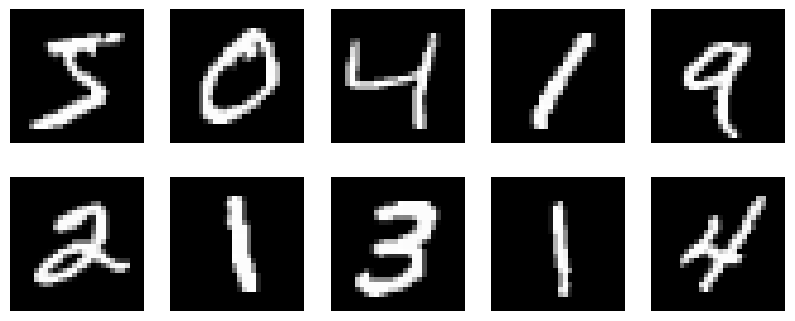

In [16]:
plt.figure(figsize=(10,4))

for i in range(10):
  plt.subplot(2,5,i+1)
  plt.imshow(x_train[i],cmap="gray")
  plt.axis("off")
plt.show()

4 - Preprocessing the images

In [17]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1,784)
x_test = x_test.reshape(-1,784)

print(x_train.shape)

(60000, 784)


5 - Defining the Encoder

In [28]:
input_layer = Input(shape=(784,))

encoded = Dense(128,activation="relu")(input_layer)

latent = Dense(32,activation="relu")(encoded)

6 - Defining the Decoder

In [32]:
decoded = Dense(128,activation="relu")(latent)

output_layer = Dense(784,activation="sigmoid")(decoded)

7 - building the complete autoencoder

In [33]:
autoencoder = Model(input_layer,output_layer)
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)
autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

8 - Training the autoencoder

In [34]:
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=5,
    batch_size=256,
    shuffle = True,
    validation_data = (x_test,x_test)
)

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.2311 - val_loss: 0.1521
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.1353 - val_loss: 0.1204
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1159 - val_loss: 0.1094
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.1077 - val_loss: 0.1035
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.1030 - val_loss: 0.1004
